# ESOL 溶解度：多模态融合（晚期拼接 + 消融）

在 `07` 的 **同一数据、同一随机划分** 上，把多种分子表示做成可开关的塔，再 **concat → MLP** 预测 `logS`。

| 塔 | 表示 | 来源 |
|----|------|------|
| Desc | 6 维 RDKit 描述符 | 与 `07` MLP 一致 |
| GNN | 原子图消息传递 → 图向量 | 与 `07` Tiny GNN 同构，去掉原回归头 |
| Seq | SMILES Transformer → 句向量 | 与 `07` 打分器式编码一致 |
| FP | Morgan 2048 → 线性压到 64 | 可选；默认消融里先不开全量四塔 |

**本笔记不做 ChemBERTa**（可选后续加）。目标：回答「融合是否优于最好的单模态」。

**损失** MSE；**指标** RMSE / R²。


In [1]:
import os
import re
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# ---------- paths / seed ----------
_NB_DIR = Path.cwd()
if (_NB_DIR / "data" / "delaney-processed.csv").exists():
    DATA_PATH = _NB_DIR / "data" / "delaney-processed.csv"
elif (_NB_DIR / ".." / "data" / "delaney-processed.csv").exists():
    DATA_PATH = (_NB_DIR / ".." / "data" / "delaney-processed.csv").resolve()
else:
    DATA_PATH = Path(r"d:\MachineLearning\aidd\data\delaney-processed.csv")

RANDOM_STATE = 42
MAX_LEN = 100
DEVICE = torch.device("cpu")
EPOCHS = 120
BATCH_SIZE = 32
LR = 1e-3
FP_PROJ = 64  # Morgan 压维后的塔输出

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

print("cwd:", Path.cwd())
print("data:", DATA_PATH, DATA_PATH.exists())
print("device:", DEVICE)


cwd: d:\MachineLearning\aidd\notebooks
data: D:\MachineLearning\aidd\data\delaney-processed.csv True
device: cpu


In [2]:
# ---------- load ESOL ----------
df = pd.read_csv(DATA_PATH)
df = df.rename(columns={"measured log solubility in mols per litre": "logS"})
df = df[["Compound ID", "smiles", "logS"]].copy()
print(df.shape)
df.head(3)


(1128, 3)


,Compound ID,smiles,logS
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,citral,CC(C)=CCCC(C)=CC(=O),-2.06


In [3]:
# ---------- featurizers (aligned with 07) ----------
DESC_FUNCS = [
    Descriptors.MolWt,
    Descriptors.MolLogP,
    Descriptors.NumHDonors,
    Descriptors.NumHAcceptors,
    Descriptors.NumRotatableBonds,
    Descriptors.TPSA,
]
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)


# 输入smiles，输出储存了 分子描述符、分子指纹信息的两个列表
def featurize_desc_fp(smiles: str):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None, None
    desc = np.array([f(mol) for f in DESC_FUNCS], dtype=np.float32)
    fp = morgan_gen.GetFingerprint(mol)
    fp_arr = np.zeros((2048,), dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, fp_arr)
    return desc, fp_arr


ELEMENTS = ["C", "N", "O", "F", "P", "S", "Cl", "Br", "I"]
ELEM2IDX = {e: i for i, e in enumerate(ELEMENTS)}
F_DIM = len(ELEMENTS) + 1 + 3  # 9元素 + 其他元素 + 度数（与几个节点相连） + 是否在苯环上 + 形式电荷


# 将smiles转换为graph形式，反回分子表示、节点邻接两个矩阵
def mol_to_graph(smiles: str):
    m = Chem.MolFromSmiles(smiles)
    if m is None or m.GetNumAtoms() == 0:
        return None
    n = m.GetNumAtoms()
    X = np.zeros((n, F_DIM), dtype=np.float32)    # X：0/1 矩阵表示整个分子。行：分子里第几个原子  列：这个原子的13维特征
    for atom in m.GetAtoms():
        i = atom.GetIdx()
        sym = atom.GetSymbol()
        if sym in ELEM2IDX:
            X[i, ELEM2IDX[sym]] = 1.0
        else:
            X[i, len(ELEMENTS)] = 1.0
        X[i, len(ELEMENTS) + 1] = atom.GetDegree()
        X[i, len(ELEMENTS) + 2] = 1.0 if atom.GetIsAromatic() else 0.0
        X[i, len(ELEMENTS) + 3] = float(np.clip(atom.GetFormalCharge(), -2, 2))
    A = np.eye(n, dtype=np.float32)             # 用边提取 节点的双向邻接矩阵，表示哪些原子相连（自环）
    for bond in m.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        A[i, j] = A[j, i] = 1.0
    deg = A.sum(axis=1, keepdims=True)   # 行归一化，邻居数 + 自身
    A_norm = A / np.maximum(deg, 1.0)
    return X, A_norm


descs, fps, graphs, smiles_ok, ys = [], [], [], [], []
for smi, y in zip(df["smiles"], df["logS"]):
    d, f = featurize_desc_fp(smi)
    g = mol_to_graph(smi)
    if d is None or g is None:
        continue
    descs.append(d)
    fps.append(f)
    graphs.append(g)
    smiles_ok.append(smi)
    ys.append(float(y))

X_desc = np.vstack(descs)                 # (样本数, 6)
X_fp = np.vstack(fps)                     # (样本数, 2048)
y = np.asarray(ys, dtype=np.float32)      # (样本数,)
print("kept", len(y), "desc", X_desc.shape, "fp", X_fp.shape, "graphs", len(graphs))


kept 1128 desc (1128, 6) fp (1128, 2048) graphs 1128


In [4]:
# ---------- same 80/20 index split as 07 ----------
idx = np.arange(len(y))
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=RANDOM_STATE)

desc_mean = X_desc[idx_train].mean(axis=0)         # 测试集不参与避免信息泄露，模拟真实场景，新分子用同一套变换
desc_std = X_desc[idx_train].std(axis=0) + 1e-8   
X_desc_z = (X_desc - desc_mean) / desc_std    # 做 Z-score 标准化（减均值、除标准差），让 6 维特征尺度接近，方便神经网络训练。

print("train", len(idx_train), "test", len(idx_test))


train 902 test 226


## Tokenizer（仅在训练集建词表）


In [5]:
class SMILESTokenizer:
    def __init__(self, max_len=100):
        self.max_len = max_len
        self.pattern = (
            r"(\[[^\]]+]|Br?|Cl?|N|O|S|P|F|I|b|c|n|o|s|p|"
            r"\(|\)|\.|=|#|-|\+|\\\\|/|:|~|@|\?|>|\*|\$|%[0-9]{2}|[0-9])"
        )
        self.regex = re.compile(self.pattern)
        self.pad_token, self.unk_token = "<pad>", "<unk>"
        self.sos_token, self.eos_token = "<sos>", "<eos>"
        self.special_tokens = [self.pad_token, self.unk_token, self.sos_token, self.eos_token]
        self.vocab = {t: i for i, t in enumerate(self.special_tokens)}
        self.inv_vocab = {i: t for t, i in self.vocab.items()}

    def tokenize(self, smiles):
        return self.regex.findall(smiles)

    def build_vocab(self, smiles_list):
        from collections import Counter
        counter = Counter()
        for smi in smiles_list:
            counter.update(self.tokenize(smi))
        for token, _ in counter.most_common():
            if token not in self.vocab:
                idx = len(self.vocab)
                self.vocab[token] = idx
                self.inv_vocab[idx] = token
        return self

    def encode(self, smiles, pad=True):
        tokens = self.tokenize(smiles)
        if len(tokens) > self.max_len - 2:
            tokens = tokens[: self.max_len - 2]
        unk = self.vocab[self.unk_token]
        ids = [self.vocab.get(t, unk) for t in tokens]
        ids = [self.vocab[self.sos_token]] + ids + [self.vocab[self.eos_token]]
        if pad and len(ids) < self.max_len:
            ids = ids + [self.vocab[self.pad_token]] * (self.max_len - len(ids))
        return ids


tok = SMILESTokenizer(max_len=MAX_LEN).build_vocab([smiles_ok[i] for i in idx_train])
PAD_ID = tok.vocab[tok.pad_token]
print("vocab", len(tok.vocab), "pad", PAD_ID)


vocab 31 pad 0


## Dataset / collate

每个样本打包：标准化描述符、指纹、图 `(X,A)`、SMILES ids、标签。  
图原子数可变，collate 里用 **list** 保存，前向时逐图过 GNN 再 stack。


In [6]:
class MultiModalDataset(Dataset):
    def __init__(self, indices):
        self.indices = list(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):    # i：Dataset 内第几个；j：全局第几个分子
        j = self.indices[i]
        X, A = graphs[j]
        return {
            "desc": torch.tensor(X_desc_z[j], dtype=torch.float32),
            "fp": torch.tensor(X_fp[j], dtype=torch.float32),
            "X": torch.tensor(X, dtype=torch.float32),
            "A": torch.tensor(A, dtype=torch.float32),
            "input_ids": torch.tensor(tok.encode(smiles_ok[j]), dtype=torch.long),
            "y": torch.tensor(y[j], dtype=torch.float32),
        }


def collate_mm(batch):
    return {
        "desc": torch.stack([i["desc"] for i in batch]),   # 堆叠返回[batch, 6]张量
        "fp": torch.stack([i["fp"] for i in batch]),
        "graphs": [(i["X"], i["A"]) for i in batch],       # 分子用graph表示后X、A形状不同，不堆叠。一个"graphs"键对应batch个二元组
        "input_ids": torch.stack([i["input_ids"] for i in batch]),
        "y": torch.stack([i["y"] for i in batch]),
    }


# DataLoader返回字典，储存5个键值对，除了"graphs"对应X、A二元组列表，其他都是矩阵
train_loader = DataLoader(MultiModalDataset(idx_train), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_mm)
test_loader = DataLoader(MultiModalDataset(idx_test), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_mm)
print("batches train/test", len(train_loader), len(test_loader))


batches train/test 29 8


## 各模态塔 + 融合头

- `GNNEncoder`：两层消息传递 + mean pool → 64 维（无回归头）
- `SeqEncoder`：双向 Transformer + 非 pad mean pool → 128 维
- `DescTower` / `FpTower`：MLP 压到与融合一致的宽度
- `FusionRegressor(mode=...)`：按 mode 选择塔，**concat 后 MLP → logS**


In [7]:
class GNNEncoder(nn.Module):
    def __init__(self, in_dim=F_DIM, hidden=64):
        super().__init__()
        self.lin1 = nn.Linear(in_dim, hidden)
        self.lin2 = nn.Linear(hidden, hidden)
        self.out_dim = hidden

    # redout分子级向量。对行做平均，用一个13维向量表示整个分子
    def encode_one(self, X, A):
        H = F.relu(A @ self.lin1(X))
        H = F.relu(A @ self.lin2(H))
        return H.mean(dim=0)   

        # GNN消息传递【核心】
        # --- A @ Z 消息传递示意（原子链 0—1—2，A 含自环且行归一化）---
        # A = [[1/2, 1/2,  0 ],
        #      [1/3, 1/3, 1/3],
        #      [ 0 , 1/2, 1/2]]
        # X = [[a1, a2],   # 原子 0
        #      [b1, b2],   # 原子 1
        #      [c1, c2]]   # 原子 2
        # A @ X =
        #   原子0: [1/2*a1 + 1/2*b1,  1/2*a2 + 1/2*b2]   # 自己 + 邻居1
        #   原子1: [1/3*(a1+b1+c1),   1/3*(a2+b2+c2)]   # 自己 + 两端
        #   原子2: [1/2*b1 + 1/2*c1,  1/2*b2 + 1/2*c2]   # 自己 + 邻居1
        # 即 H[i] = sum_j A[i,j]*Z[j]；第二层后再做一次可传到 2-hop。
        # mean(dim=0) 对原子维平均 → 整图向量。
        
    # 返回[32, 64]矩阵，每一行表示一个分子的13维特征
    def forward(self, graph_list):
        return torch.stack([self.encode_one(X.to(DEVICE), A.to(DEVICE)) for X, A in graph_list], dim=0)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class SeqEncoder(nn.Module):
    def __init__(self, vocab_size, d_model=128, nhead=4, num_layers=2, dim_ff=256, pad_idx=0, dropout=0.1):
        super().__init__()
        self.pad_idx = pad_idx
        self.d_model = d_model
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=dropout, batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.out_dim = d_model


    # 返回[32, 128]矩阵，每一行一个句向量，
    def forward(self, input_ids):
        pad_mask = input_ids.eq(self.pad_idx)   # .eq() 是PyTorch张量上逐元素相等比较，返回一个input_ids同形状的布尔张量
        h = self.embedding(input_ids) * math.sqrt(self.d_model)
        h = self.pos(h)
        h = self.encoder(h, src_key_padding_mask=pad_mask)
        keep = (~pad_mask).unsqueeze(-1).float()      # [B, L] → [B, L, 1]变形才能与 h 相乘
        return (h * keep).sum(1) / keep.sum(1).clamp(min=1e-9)   # 非pad位token求和 / 非pad个数 = 对L维平均池化，得到一个d维句向量代表整个分子


class FusionRegressor(nn.Module):
    # mode: desc | gnn | seq | fp | gnn+desc | gnn+seq | gnn+desc+seq | all

    def __init__(self, mode, vocab_size, pad_idx, desc_dim=6, fp_dim=2048):
        super().__init__()
        self.mode = mode
        if mode == "all":
            parts = ["gnn", "desc", "seq", "fp"]
        else:
            parts = mode.split("+")
        self.use = set(parts)

        self.gnn = GNNEncoder() if "gnn" in self.use else None
        self.seq = SeqEncoder(vocab_size, pad_idx=pad_idx) if "seq" in self.use else None
        self.desc = nn.Sequential(
            nn.Linear(desc_dim, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 64), nn.ReLU(),
        ) if "desc" in self.use else None
        self.fp = nn.Sequential(
            nn.Linear(fp_dim, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, FP_PROJ), nn.ReLU(),
        ) if "fp" in self.use else None

        fusion_dim = 0
        if self.gnn: fusion_dim += self.gnn.out_dim   # 64
        if self.seq: fusion_dim += self.seq.out_dim   # 128
        if self.desc: fusion_dim += 64                # 64
        if self.fp: fusion_dim += FP_PROJ             # 64

        self.head = nn.Sequential(
            nn.Linear(fusion_dim, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, batch):    # batch是DataLoader返回的字典
        feats = []
        if self.gnn is not None:
            feats.append(self.gnn(batch["graphs"]))                 # graphs是X、A二元组列表，模型返回[32, 64]矩阵
        if self.seq is not None:
            feats.append(self.seq(batch["input_ids"].to(DEVICE)))   # input_ids是[32, 100]矩阵，模型返回[32, 128]矩阵
        if self.desc is not None:
            feats.append(self.desc(batch["desc"].to(DEVICE)))       # desc是[32, 6]矩阵，模型返回[32, 64]矩阵
        if self.fp is not None:
            feats.append(self.fp(batch["fp"].to(DEVICE)))           # fp是[32, 2048]矩阵，模型返回[32, 64]矩阵
        # torch.cat = concatenate（拼接）：把多个张量沿某个维度首尾接成一个更长的张量，不新建“外层 batch 维”（那是 stack 的事）
        return self.head(torch.cat(feats, dim=-1)).squeeze(-1)


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


In [8]:
def run_mode(mode, epochs=EPOCHS, lr=LR):
    """Train one fusion mode.
    每个 epoch：记录 train/test MSE（同尺度，便于看过拟合）。
    训练结束后：再算一次 test RMSE / R2 作为最终评价。
    注：严格做法应用独立 validation 监控；此处用 test 仅作教学监控。
    """
    model = FusionRegressor(mode, len(tok.vocab), PAD_ID).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    mse = nn.MSELoss()
    hist = []  # list of (train_mse, test_mse)

    for epoch in range(1, epochs + 1):
        model.train()
        total, n = 0.0, 0
        for batch in train_loader:
            yb = batch["y"].to(DEVICE)
            opt.zero_grad()
            pred = model(batch)
            loss = mse(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(yb)
            n += len(yb)
        tr = total / max(n, 1)

        model.eval()
        te_total, te_n = 0.0, 0
        ys, ps = [], []
        with torch.no_grad():
            for batch in test_loader:
                yb = batch["y"].to(DEVICE)
                pred = model(batch)
                te_total += mse(pred, yb).item() * len(yb)
                te_n += len(yb)
                ys.append(batch["y"].numpy())
                ps.append(pred.cpu().numpy())
        te = te_total / max(te_n, 1)
        hist.append((tr, te))
        if epoch == 1 or epoch % 20 == 0 or epoch == epochs:
            print(f"[{mode:16s}] ep {epoch:3d}  trainMSE={tr:.4f}  testMSE={te:.4f}")

    yt, yp = np.concatenate(ys), np.concatenate(ps)
    rmse = float(np.sqrt(mean_squared_error(yt, yp)))
    r2 = float(r2_score(yt, yp))
    print(f"  final  testRMSE={rmse:.4f}  R2={r2:.4f}  params={count_params(model):,}")
    return {"mode": mode, "rmse": rmse, "r2": r2, "hist": hist, "y_true": yt, "y_pred": yp}


# 消融：单模态 → 双模态 → 三模态（先不加 fp，避免小样本过宽）
MODES = [
    "desc",
    "gnn",
    "seq",
    "gnn+desc",
    "gnn+seq",
    "desc+seq",
    "gnn+desc+seq",
]

results = []
for mode in MODES:
    print("\n" + "=" * 60)
    results.append(run_mode(mode))



[desc            ] ep   1  trainMSE=8.7800  testMSE=3.9358
[desc            ] ep  20  trainMSE=0.6002  testMSE=0.8163
[desc            ] ep  40  trainMSE=0.4848  testMSE=0.8181
[desc            ] ep  60  trainMSE=0.4671  testMSE=0.6916
[desc            ] ep  80  trainMSE=0.4684  testMSE=0.6544
[desc            ] ep 100  trainMSE=0.4032  testMSE=0.7003
[desc            ] ep 120  trainMSE=0.4079  testMSE=0.7009
  final  testRMSE=0.8372  R2=0.8517  params=21,249

[gnn             ] ep   1  trainMSE=11.1749  testMSE=5.8400
[gnn             ] ep  20  trainMSE=1.9810  testMSE=2.3846
[gnn             ] ep  40  trainMSE=1.7724  testMSE=2.0155
[gnn             ] ep  60  trainMSE=1.6154  testMSE=1.7871
[gnn             ] ep  80  trainMSE=1.4606  testMSE=1.6037
[gnn             ] ep 100  trainMSE=1.3740  testMSE=1.5500
[gnn             ] ep 120  trainMSE=1.4723  testMSE=1.4847
  final  testRMSE=1.2185  R2=0.6859  params=21,697



d:\MachineLearning\.venv\Lib\site-packages\torch\nn\modules\transformer.py:529: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(


[seq             ] ep   1  trainMSE=6.2493  testMSE=4.4787
[seq             ] ep  20  trainMSE=0.7761  testMSE=0.8843
[seq             ] ep  40  trainMSE=0.6063  testMSE=0.7246
[seq             ] ep  60  trainMSE=0.5613  testMSE=0.5424
[seq             ] ep  80  trainMSE=0.5185  testMSE=0.6175
[seq             ] ep 100  trainMSE=0.4771  testMSE=0.6771
[seq             ] ep 120  trainMSE=0.4808  testMSE=0.6216
  final  testRMSE=0.7884  R2=0.8685  params=293,761

[gnn+desc        ] ep   1  trainMSE=8.8901  testMSE=4.9217
[gnn+desc        ] ep  20  trainMSE=0.5279  testMSE=0.7779
[gnn+desc        ] ep  40  trainMSE=0.4885  testMSE=0.6986
[gnn+desc        ] ep  60  trainMSE=0.4529  testMSE=0.7724
[gnn+desc        ] ep  80  trainMSE=0.3916  testMSE=0.6593
[gnn+desc        ] ep 100  trainMSE=0.4138  testMSE=0.6601
[gnn+desc        ] ep 120  trainMSE=0.3412  testMSE=0.6317
  final  testRMSE=0.7948  R2=0.8664  params=34,497

[gnn+seq         ] ep   1  trainMSE=6.8921  testMSE=4.6392
[gnn+seq  

        mode     RMSE       R2
    desc+seq 0.726846 0.888232
gnn+desc+seq 0.749613 0.881121
         seq 0.788440 0.868487
    gnn+desc 0.794767 0.866368
     gnn+seq 0.802005 0.863922
        desc 0.837209 0.851714
         gnn 1.218473 0.685902

best: desc+seq  RMSE=0.7268  R2=0.8882


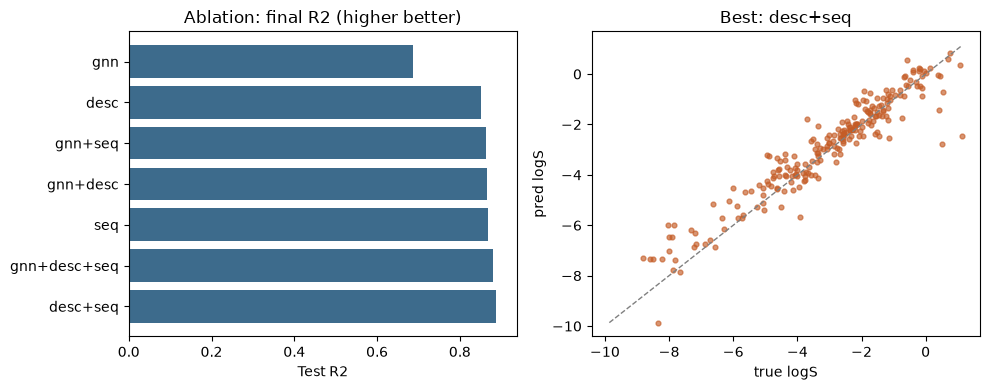

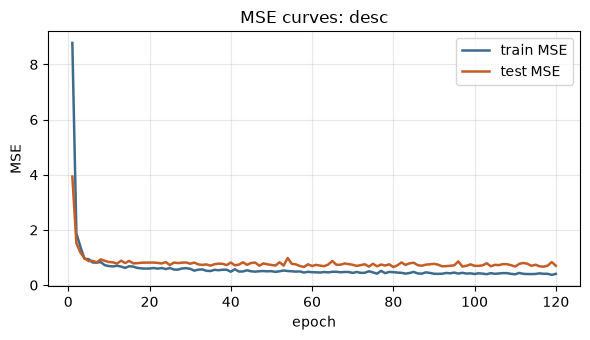

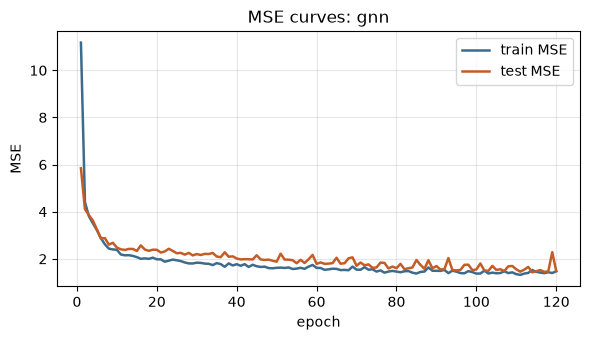

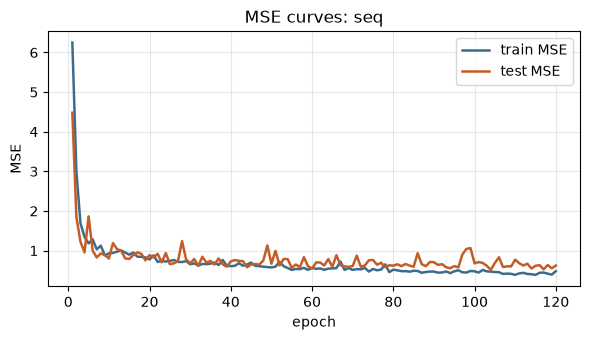

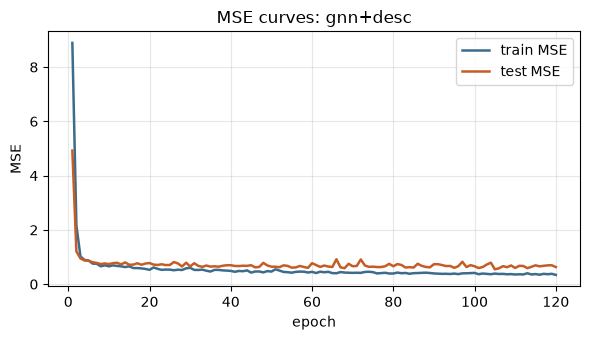

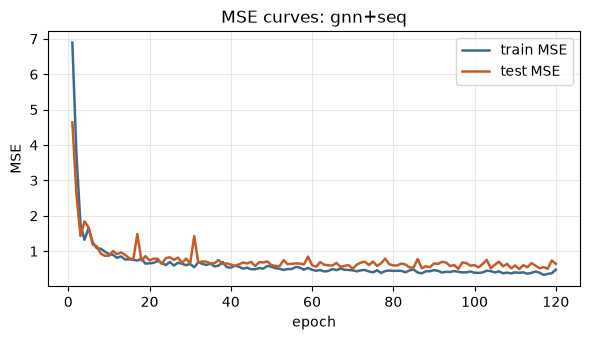

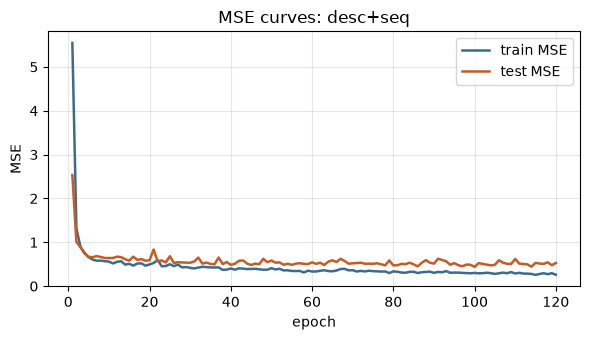

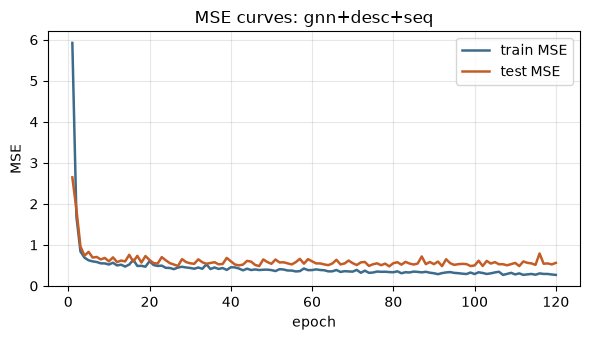

In [9]:
# ---------- summary table + plots ----------
summary = pd.DataFrame([{"mode": r["mode"], "RMSE": r["rmse"], "R2": r["r2"]} for r in results])
summary = summary.sort_values("RMSE")
print(summary.to_string(index=False))

best = min(results, key=lambda r: r["rmse"])
print(f"\nbest: {best['mode']}  RMSE={best['rmse']:.4f}  R2={best['r2']:.4f}")

# 汇总：R2 条形图 + 最优模型散点
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.barh(summary["mode"], summary["R2"], color="#3d6b8c")
ax.set_xlabel("Test R2")
ax.set_title("Ablation: final R2 (higher better)")
ax.set_xlim(0, max(0.05, summary["R2"].max() + 0.05))

ax = axes[1]
ax.scatter(best["y_true"], best["y_pred"], s=12, alpha=0.65, color="#c45c26")
lims = [min(best["y_true"].min(), best["y_pred"].min()),
        max(best["y_true"].max(), best["y_pred"].max())]
ax.plot(lims, lims, "--", color="gray", linewidth=1)
ax.set_xlabel("true logS")
ax.set_ylabel("pred logS")
ax.set_title(f"Best: {best['mode']}")

plt.tight_layout()
plt.show()

# 各 mode 单独一张：train / test MSE 曲线（便于看过拟合）
for r in results:
    tr_hist = [h[0] for h in r["hist"]]
    te_hist = [h[1] for h in r["hist"]]
    epochs = range(1, len(tr_hist) + 1)

    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(epochs, tr_hist, label="train MSE", color="#3d6b8c", linewidth=1.8)
    ax.plot(epochs, te_hist, label="test MSE", color="#c45c26", linewidth=1.8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("MSE")
    ax.set_title(f"MSE curves: {r['mode']}")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## 可选：加上指纹塔再跑一次

若上面最优是 `gnn+desc+seq`，可再比 `all`（含 FP）。指纹维数高，小数据上不一定涨点。


In [10]:
# 取消注释以跑含指纹的全融合
# r_all = run_mode("all")
# print(r_all["mode"], r_all["rmse"], r_all["r2"])


## 解读提示

1. 若 `gnn+desc` 明显好于 `gnn` / `desc`：物化描述符与结构图互补（溶解度常见）。
2. 若 `gnn+desc+seq` 几乎不涨：序列塔与图信息重叠，可消融掉 seq 减参。
3. 与 `07` 对照时请用 **同一 `RANDOM_STATE=42` 划分**；本笔记未重训 RF，请直接引用 `07` 的 RF 数字作外部基线。
4. ChemBERTa 预训练塔：需 `transformers` + 下载权重，建议特征缓存后再加第四/第五塔消融。
